# Follow-up: why were some engines badly overestimated?

Same steps as `src/06_engine_baselines.py`, with explanations.

Week 4 found 5 test engines near failure that the best model guessed 23 to 54 flights too high. This notebook finds the cause and tests a fix. *(It trains about 30 models and takes a few minutes.)*

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore', message='.*encountered in matmul')
%matplotlib inline
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from cmapss import (RUL_CAP, load_train, clip_rul, feature_columns, load_test_last_rows, rmse,
                    add_baseline_features, starting_score, cross_validate_by_engine,
                    plot_predicted_vs_true)

N_START, SMOOTH = 20, 10
train = load_train()
train_c = clip_rul(train)
features = feature_columns(train)

def new_gb():
    return GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=0)

## The idea

Every engine begins life at a slightly different sensor level, like people with different resting heart rates. The model judged all engines on one shared scale. An engine that starts out looking extra healthy can be badly worn and still show numbers that look normal.

**The fix:** add clues that say *how far has each sensor moved from this engine's own starting level* (the average of its first 20 flights). These clues only ever use flights that have already happened.

In [2]:
train_b = add_baseline_features(train_c, N_START, smooth=SMOOTH)
chg = [c for c in train_b.columns if c.endswith('_chg')]
chg_smooth = [c for c in train_b.columns if c.endswith(f'_chg_avg{SMOOTH}')]
clue_sets = {'Original 17 clues': features,
             '+ change from own start': features + chg,
             '+ change, also smoothed': features + chg + chg_smooth}
# No-peeking check: rebuild the clues with every flight after 60 deleted.
# If the clues for flights 1-60 come out identical, they never use the future.
a = train_b[train_b.cycle <= 60][chg + chg_smooth].to_numpy()
b = add_baseline_features(train_c[train_c.cycle <= 60], N_START, smooth=SMOOTH)[chg + chg_smooth].to_numpy()
print('largest difference:', np.abs(a - b).max())

largest difference: 0.0


## Step 1: The cause, measured on training engines only

Each training engine is predicted by a model that never saw it. Engines are grouped by how healthy they looked in their first 20 flights, and we look at the average miss when they are 15 to 30 flights from failure.

In [3]:
def held_out_predictions(df, cols):
    out = np.zeros(len(df))
    for tr, va in GroupKFold(n_splits=5).split(df, groups=df.unit):
        out[va] = new_gb().fit(df.iloc[tr][cols], df.iloc[tr].RUL).predict(df.iloc[va][cols])
    return out

start = starting_score(train)
near = ((train_c.RUL >= 15) & (train_c.RUL <= 30)).to_numpy()
group = pd.qcut(start, 4, labels=['lowest', 'low', 'high', 'healthiest-looking'])
table = {}
for name in ['Original 17 clues', '+ change from own start']:
    pred = held_out_predictions(train_b, clue_sets[name])
    per_engine = pd.Series(pred - train_c.RUL.to_numpy())[near].groupby(train_c.unit.to_numpy()[near]).mean()
    table[name] = per_engine.groupby(group[per_engine.index], observed=True).mean()
pd.DataFrame(table).T.round(1)

,lowest,low,high,healthiest-looking
Original 17 clues,-2.8,1.7,10.7,13.0
+ change from own start,1.2,1.2,2.0,3.6


**Reading the table:** with the original clues, engines that started out looking healthiest are guessed about 13 flights too high near failure. With the new clues that drops to about 4, and all four groups are treated nearly the same.

## Step 2: Five practice exams

In [4]:
rows = []
for name, cols in clue_sets.items():
    mean, folds = cross_validate_by_engine(new_gb, train_b, cols)
    rows.append({'clues': name, 'average RMSE': mean, 'lowest exam': min(folds), 'highest exam': max(folds)})
pd.DataFrame(rows).round(2)

,clues,average RMSE,lowest exam,highest exam
0,Original 17 clues,18.57,16.55,20.51
1,+ change from own start,13.68,12.93,14.40
2,"+ change, also smoothed",12.41,12.04,13.20


Every one of the five exams improves by 4 to 7 flights. Compare Week 3, where rolling averages moved the score by a few tenths. This is a real effect, not noise.

## Step 3: Test set

In [5]:
test_last = load_test_last_rows(add_features=lambda df: add_baseline_features(df, N_START, smooth=SMOOTH))
truth = test_last.RUL
near_t = (truth <= 30).to_numpy()
preds, rows = {}, []
for name, cols in clue_sets.items():
    preds[name] = new_gb().fit(train_b[cols], train_b.RUL).predict(test_last[cols])
    err = preds[name] - truth
    rows.append({'clues': name, 'test RMSE': rmse(truth, preds[name]), 'too high (of 100)': int((err > 0).sum()),
                 'RMSE near failure': rmse(truth[near_t], preds[name][near_t]),
                 'near failure, >20 too high': int((err[near_t] > 20).sum())})
pd.DataFrame(rows).round(2)

,clues,test RMSE,too high (of 100),RMSE near failure,"near failure, >20 too high"
0,Original 17 clues,18.36,53,18.34,5
1,+ change from own start,14.78,48,7.13,0
2,"+ change, also smoothed",15.18,53,7.47,0


In [6]:
five = test_last[test_last.unit.isin([41, 37, 18, 64, 61])][['unit', 'RUL']].copy()
five['before'] = preds['Original 17 clues'][five.index].round()
five['after'] = preds['+ change, also smoothed'][five.index].round()
five

,unit,RUL,before,after
17,18,28,70.0,39.0
36,37,21,65.0,28.0
40,41,18,72.0,30.0
60,61,21,44.0,30.0
63,64,28,55.0,36.0


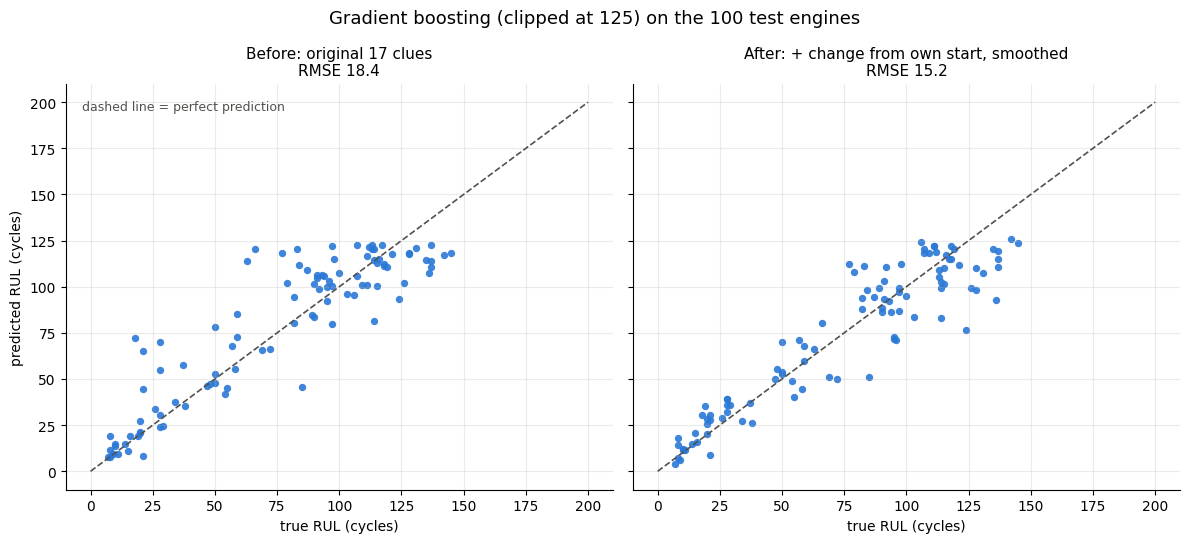

In [7]:
fig = plot_predicted_vs_true(
    [('Before: original 17 clues', truth, preds['Original 17 clues']),
     ('After: + change from own start, smoothed', truth, preds['+ change, also smoothed'])],
    f'Gradient boosting (clipped at {RUL_CAP}) on the 100 test engines', limit=200)

**Result:** test RMSE falls from 18.36 to about 15. Near failure the error falls from 18 to about 7, and no near-failure engine is more than 20 flights too high any more.

**Honest notes:**
- The practice exams preferred the smoothed version; the test set slightly preferred the plain one (14.78 vs 15.18). With 100 engines that gap is noise, so I report the one the practice exams chose: **15.18**.
- I got this idea by studying mistakes on the test set, so the test set is no longer a perfectly fresh exam for this change. The cause and the fix were both confirmed on training engines only, which is why I trust it.
- The five engines are still guessed 8 to 12 flights too high. Better, not solved.